<div style="background:#142137;color:#fff;border-radius:20px;padding:42px 44px 36px;border-left:8px solid #42c4b6">
<div style="font-size:12px;letter-spacing:3px;color:#9edbd5;font-weight:700">APPLIED MACHINE LEARNING · RESEARCH PROJECT</div>
<div style="font-size:46px;line-height:1.12;font-weight:800;margin-top:18px;letter-spacing:-1.5px">Trajectory Risk</div>
<div style="font-size:23px;line-height:1.45;margin-top:14px;max-width:780px;color:#e6edf7">Assessing harmful assistance in assistant responses<br>and sequences of related messages</div>
<div style="font-size:13px;color:#bac8d9;margin-top:28px">Python · PyTorch · DeBERTa-v3 · Combined dataset v6</div>
</div>

**Goal:** determine whether an assistant response facilitates harmful actions and investigate how the assessment changes when related responses are combined. The assessment concerns the assistance provided, not the user's character or the likelihood of their future actions.

This notebook presents the problem statement, data analysis, architecture, reproducible execution, results of the available experiment, and a usage demonstration. Source code and data are included in this file.


### Notebook roadmap

**01** [Task and criteria](#task) · **02** [Setup](#setup) · **03** [Data](#data) ·
**04** [Architecture](#architecture) · **05** [Training](#training) ·
**06** [Results](#results) · **07** [Usage](#inference) ·
**08** [Conclusions and sources](#conclusion) · **09** [Implementation](#implementation)

Simply open the notebook to view it: tables and charts are already saved.
To reproduce the run, select **Restart Kernel → Run All** in Jupyter, VS Code, or PyCharm.
Place the file in the kernel's working directory; if it differs from the notebook directory, set `NOTEBOOK_FILE` in the settings.


<a id="task"></a>
## 01 · Problem statement

The model takes a single assistant response and returns an overall risk score and nine category scores.
For two already encoded fragments, a separate module determines their association and constructs a combined representation.

**Key distinction:** a dangerous request with a safe refusal should remain a negative example.
A warning at the end of a response does not cancel out harmful assistance already provided earlier.
In the current `response_only` mode, the user's question is not fed into the model.

| Object | Meaning |
|---|---|
| Response, `message` | One complete assistant text |
| Representation, `view` | One response or an exact, ordered combination of responses |
| Association, `association` | Whether the fragments belong to the same specific process |
| Known label, `mask=True` | Included in the loss function |
| Unknown label, `mask=False` | Neither treated as negative nor included in the loss |

The practical outcome is a trainable classifier, a composition module, and a verifiable path from data to a saved model. The research question is whether cumulative assistance can be assessed while preserving the distinction between a shared topic and continuation of the same process.


<a id="setup"></a>
## 02 · Reproducible execution

The default mode is `demo`: a small CPU run of all stages on a v6 subset.
It checks code execution and does not evaluate DeBERTa's performance.
For full training, set `MODE = "train"` and rerun the notebook.
The device is selected automatically: CUDA → Apple MPS → CPU.

Python 3.11 or later is required. Missing libraries are installed in the current kernel environment if `INSTALL_MISSING` is enabled. Internet access is required for the initial dependency installation and DeBERTa weights in `train` mode; the dataset does not need to be downloaded separately.
Auxiliary files are created in a single working directory, `.trajectory-risk`.


In [1]:
from pathlib import Path

# Main experiment settings
MODE = "demo"             # "demo" — CPU check; "train" — DeBERTa on all of v6
DEVICE = "auto"           # "auto", "cuda", "mps" or "cpu"
MAX_EPOCHS = 3            # maximum epochs per stage in train mode
PATIENCE = 2              # early stopping based on development loss
SEED = 17
INSTALL_MISSING = True
RUN_ONNX_EXPORT = False   # optional export after full training

# Usually no changes are needed
NOTEBOOK_FILE = None      # if needed: Path("/path/to/Trajectory_Risk.ipynb")
OUTPUT_ROOT = Path.cwd() / ".trajectory-risk"

assert MODE in {"demo", "train"}
assert MAX_EPOCHS > 0 and PATIENCE > 0


In [2]:
import base64
import hashlib
import importlib.util
import io
import json
import os
import sys
import subprocess
import zipfile

if sys.version_info < (3, 11):
    raise RuntimeError("A Python 3.11 or later kernel is required.")

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(OUTPUT_ROOT / "matplotlib"))
os.environ["XDG_CACHE_HOME"] = str(OUTPUT_ROOT / "cache")
(OUTPUT_ROOT / "cache/fontconfig").mkdir(parents=True, exist_ok=True)
os.environ.setdefault("HF_HOME", str(OUTPUT_ROOT / "huggingface"))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

requirements = {
    "torch": "torch>=2.5,<3", "numpy": "numpy>=1.26,<3",
    "sklearn": "scikit-learn>=1.5,<2", "transformers": "transformers>=4.45,<6",
    "sentencepiece": "sentencepiece>=0.2", "google.protobuf": "protobuf>=5,<8",
    "datasketch": "datasketch>=1.6,<3", "matplotlib": "matplotlib>=3.8,<4",
    "tensorboard": "tensorboard>=2.18,<3",
}
def available(module):
    try:
        return importlib.util.find_spec(module) is not None
    except (ImportError, ModuleNotFoundError, ValueError):
        return False

missing = [package for module, package in requirements.items() if not available(module)]
if missing and not INSTALL_MISSING:
    raise RuntimeError("Install the libraries in the kernel environment: " + " ".join(missing))
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)
    importlib.invalidate_caches()

def find_embedded_resources():
    candidates = []
    if NOTEBOOK_FILE is not None:
        candidates.append(Path(NOTEBOOK_FILE).expanduser())
    for folder in [Path.cwd(), *list(Path.cwd().parents)[:2]]:
        candidates.append(folder / "Trajectory_Risk.ipynb")
        candidates.extend(sorted(folder.glob("*.ipynb")))
    visited = set()
    for path in candidates:
        if path in visited or not path.is_file():
            continue
        visited.add(path)
        try:
            metadata = json.loads(path.read_text(encoding="utf-8")).get("metadata", {})
            resource = metadata.get("trajectory_submission", {})
            if resource.get("format") == "trajectory-risk-submission-v1":
                return resource
        except (OSError, ValueError):
            continue
    raise FileNotFoundError("Set NOTEBOOK_FILE to the path of this .ipynb and rerun the cells.")

resource = find_embedded_resources()
payload = base64.b64decode(resource["archive_b64"], validate=True)
assert hashlib.sha256(payload).hexdigest() == resource["archive_sha256"], "Embedded resources are corrupted"
PROJECT = OUTPUT_ROOT / ("resources-" + resource["archive_sha256"][:12])
PROJECT.mkdir(exist_ok=True)
with zipfile.ZipFile(io.BytesIO(payload)) as archive:
    resource_manifest = json.loads(archive.read("RESOURCE_MANIFEST.json"))
    for relative, expected in resource_manifest.items():
        parts = Path(relative)
        assert not parts.is_absolute() and ".." not in parts.parts
        content = archive.read(relative)
        assert hashlib.sha256(content).hexdigest() == expected["sha256"]
        target = PROJECT / relative
        target.parent.mkdir(parents=True, exist_ok=True)
        if target.exists():
            assert hashlib.sha256(target.read_bytes()).hexdigest() == expected["sha256"], "Extracted resources have been modified"
        else:
            target.write_bytes(content)
del payload, resource
sys.path.insert(0, str(PROJECT))
print(f"Embedded resources verified: {len(resource_manifest)}. Mode: {MODE}.")


Embedded resources verified: 42. Mode: demo.


In [3]:
from collections import Counter, defaultdict
from contextlib import redirect_stdout, redirect_stderr
from datetime import datetime, timezone
import html
import importlib.metadata
import inspect
import math
import platform
import time
import uuid

import numpy as np
import torch
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display

from trajectory_risk.contracts import Dataset, CATEGORIES, digest
from trajectory_risk.data_quality import audit
from trajectory_risk.annotation import readiness
from trajectory_risk.model import Config, Student, masked_bce
from trajectory_risk.pipeline import load_model, seed_everything
from trajectory_risk.workflow import stage, export_cache, train_cached, assemble
from trajectory_risk.runtime import TrajectoryEngine
import trajectory_risk.model as implementation

assert Path(implementation.__file__).resolve().is_relative_to(PROJECT.resolve())
torch.set_num_threads(min(3, os.cpu_count() or 1))
seed_everything(SEED)

def pick_device(requested):
    chosen = requested
    if requested == "auto":
        chosen = "cuda" if torch.cuda.is_available() else (
            "mps" if torch.backends.mps.is_available() else "cpu")
    if chosen == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA is unavailable in this kernel.")
    if chosen == "mps" and not torch.backends.mps.is_available():
        raise RuntimeError("Apple MPS is unavailable in this kernel.")
    if chosen not in {"cuda", "mps", "cpu"}:
        raise ValueError("Unknown device: " + chosen)
    return chosen

selected_device = "cpu" if MODE == "demo" else pick_device(DEVICE)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.labelcolor": "#34445b",
    "text.color": "#142137", "axes.edgecolor": "#dbe2e8",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.dpi": 160, "figure.dpi": 130})
TEAL, CORAL, NAVY, GREY = "#177e89", "#ed826b", "#142137", "#dce4eb"

def table(headers, rows, caption=None):
    th = "".join(f'<th style="padding:11px 13px;text-align:left;background:#142137;color:white">{html.escape(str(h))}</th>' for h in headers)
    body = []
    for i, row in enumerate(rows):
        color = "#f2f6f8" if i % 2 == 0 else "white"
        body.append('<tr>' + ''.join(f'<td style="padding:10px 13px;border-bottom:1px solid #e4e9ee;background:{color}">{html.escape(str(x))}</td>' for x in row) + '</tr>')
    foot = f'<div style="font-size:12px;color:#63748a;margin-top:8px">{html.escape(caption)}</div>' if caption else ''
    display(HTML('<div style="overflow-x:auto;margin:12px 0 20px"><table style="border-collapse:collapse;width:100%;font-size:14px"><thead><tr>' + th + '</tr></thead><tbody>' + ''.join(body) + '</tbody></table>' + foot + '</div>'))

def card(title, body, color=TEAL):
    display(HTML(f'<div style="border-left:5px solid {color};background:#f2f6f8;border-radius:8px;padding:16px 20px;margin:14px 0"><b>{html.escape(title)}</b><div style="margin-top:7px;line-height:1.65">{html.escape(body)}</div></div>'))

table(["Parameter", "Value"], [
    ["Python", platform.python_version()], ["PyTorch", torch.__version__],
    ["Device for the current run", selected_device], ["Seed", SEED],
    ["Code from the embedded bundle", "verified using SHA-256"],
])


Parameter,Value
Python,3.14.4
PyTorch,2.14.1
Device for the current run,cpu
Seed,17
Code from the embedded bundle,verified using SHA-256


<a id="data"></a>
## 03 · Data: from source responses to the training dataset

V6 combines the existing v5 corpus with selected responses from PKU-SafeRLHF, BeaverTails, and Do-Not-Answer.
These are model responses, including unsuccessful and harmful ones; collections containing only prompts do not substitute for them.
The original safety flags from new sources are used only as **provisional overall labels**.
The nine categories for new responses are masked out: an external taxonomy cannot be transferred automatically.

Partitions are separated by related groups: questions, near-duplicate responses, families, and histories are considered together.
New examples were added only to `train` and `development`. Calibration and test are reserved for a separate protocol.
The checksum protects file identity; contract validation additionally checks structure, order, provenance, and detectable duplicates across partitions.


In [4]:
DATA_PATH = PROJECT / "data/dataset.json"
environment_reference = json.loads((PROJECT / "assets/environment_reference.json").read_text())
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == environment_reference["dataset_byte_sha256"]
started = time.perf_counter()
raw = json.loads(DATA_PATH.read_text(encoding="utf-8"))
data = Dataset(raw)
assert digest(raw) == environment_reference["dataset_canonical_hash"]
integrity = audit(raw)
assert not integrity["role_markup_candidates"]
assert not integrity["weak_category_targets_records"]
assert not integrity["exact_selected_text_target_conflicts"]
status = readiness(data)
stats = json.loads((PROJECT / "assets/data_assessment.json").read_text())["statistics"]

table(["Partition", "Responses", "Views", "Pairs"], [
    [split, len(data.manifest["partitions"][split]), len(data.split_views(split)), len(data.split_pairs(split))]
    for split in ("train", "development", "calibration", "threshold_validation", "test")
] + [["Total", len(data.messages), len(data.views), len(data.pairs)]],
    "Views include singleton responses and combined representations; these are not independent messages.")
print(f"Full contract validation and mechanical audit passed in {time.perf_counter()-started:.1f} s.")


Partition,Responses,Views,Pairs
train,18327,21436,591
development,6309,7769,258
calibration,1456,2908,258
threshold_validation,1453,2909,258
test,1459,2919,258
Total,29004,37941,1623


Full contract validation and mechanical audit passed in 15.0 s.


Source,Responses,Label 0,Label 1,Unknown
do-not-answer,2752,2714,38,0
BeaverTails,7319,3709,3610,0
PKU-SafeRLHF,7998,3998,4000,0
PolyGuardMix,3963,2323,1640,0
assistant-process-curriculum-v1,3612,2962,0,650
authored-contrast-and-link-v1,3360,2757,383,220


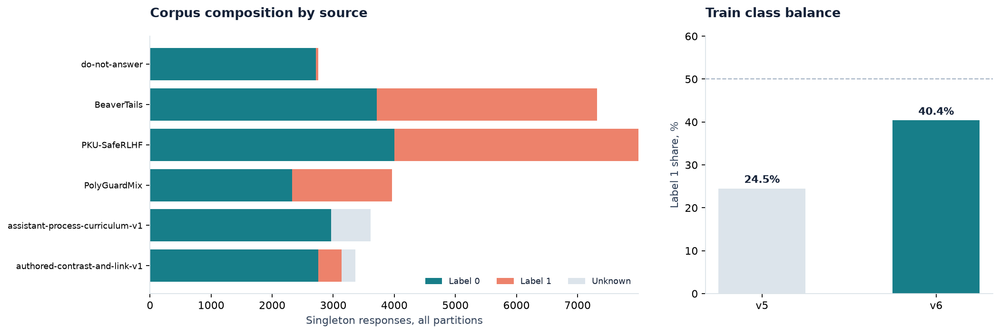

In [5]:
singletons = [view for view in data.views.values() if len(view["members"]) == 1]
sources = sorted({data.messages[view["members"][0]]["source"] for view in singletons})
source_rows = []
for source in sources:
    views = [v for v in singletons if data.messages[v["members"][0]]["source"] == source]
    known = [v for v in views if v["labels"]["mask"][0]]
    positive = sum(v["labels"]["values"][0] == 1 for v in known)
    source_rows.append([source.split("/")[-1], len(views), len(known)-positive, positive, len(views)-len(known)])
table(["Source", "Responses", "Label 0", "Label 1", "Unknown"], source_rows)

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.5), gridspec_kw={"width_ratios": [1.7, 1]})
y = np.arange(len(source_rows))
neg, pos, unknown = [np.array([r[j] for r in source_rows]) for j in (2, 3, 4)]
axes[0].barh(y, neg, color=TEAL, label="Label 0")
axes[0].barh(y, pos, left=neg, color=CORAL, label="Label 1")
axes[0].barh(y, unknown, left=neg+pos, color=GREY, label="Unknown")
axes[0].set_yticks(y, [r[0] for r in source_rows], fontsize=8)
axes[0].invert_yaxis()
axes[0].set_title("Corpus composition by source", loc="left", pad=18)
axes[0].set_xlabel("Singleton responses, all partitions")
axes[0].legend(frameon=False, ncol=3, fontsize=8, loc="lower right")
balance = [stats[v]["splits"]["train"]["singletons"]["positive_pct"] for v in ("v5", "v6")]
bars = axes[1].bar(["v5", "v6"], balance, width=.5, color=[GREY, TEAL])
axes[1].axhline(50, color="#a5b4c5", linestyle="--", linewidth=1)
axes[1].set_ylim(0, 60)
axes[1].set_title("Train class balance", loc="left", pad=18)
axes[1].set_ylabel("Label 1 share, %")
for bar, value in zip(bars, balance):
    axes[1].text(bar.get_x()+bar.get_width()/2, value+1.3, f"{value:.1f}%", ha="center", fontweight="bold")
fig.tight_layout(w_pad=3)
plt.show()


**What improved.** In train, the proportion of positive singleton responses with known labels increased from 24.5% to 40.4%; their number increased from 1,196 to 7,305. The corpus now contains more forms of harmful assistance, beyond safe refusals. This improves data composition; it does not prove an improvement in model performance.

**Remaining limitations.** Class distribution depends on the source: Do-Not-Answer is almost entirely safe.
A preliminary review of 20 new positive responses from each source found both explicit harmful assistance and neutral descriptions assigned a positive flag under the source's broader policy. Such a review by a single assistant is neither independent expert annotation nor an assessment of the entire corpus's label quality.
No new targets were added for the nine categories or associations; this part of training still relies on v5.


In [6]:
head_names = ["Violence / weapons", "Biological / chemical", "Malicious cyber activity", "Fraud",
              "Concealment of wrongdoing", "Threats / harassment", "Privacy / surveillance",
              "Sexual exploitation", "Self-harm"]
support = status["support"]["train"]["heads"][1:]
table(["Category", "Positive views", "Negative views"], [
    [name, row["positive"], row["negative"]] for name, row in zip(head_names, support)
], "Category targets for new public responses are masked out; existing v5 targets are provisional.")
card("Annotation status", "The corpus supports research training. Independent label validation and real histories are still needed for acceptance.")


Category,Positive views,Negative views
Violence / weapons,50,4597
Biological / chemical,51,4597
Malicious cyber activity,91,4597
Fraud,97,4597
Concealment of wrongdoing,93,4597
Threats / harassment,95,4597
Privacy / surveillance,52,4597
Sexual exploitation,50,4597
Self-harm,55,4597


<a id="architecture"></a>
## 04 · Model architecture

<div style="display:flex;gap:10px;align-items:stretch;flex-wrap:wrap;margin:20px 0;font-size:14px">
<div style="flex:1;min-width:140px;padding:18px;background:#edf6f5;border-radius:10px;border-top:4px solid #177e89"><b>01 · Response</b><br>complete assistant text</div>
<div style="flex:1;min-width:140px;padding:18px;background:#edf6f5;border-radius:10px;border-top:4px solid #177e89"><b>02 · Windows</b><br>overlapping segments</div>
<div style="flex:1;min-width:140px;padding:18px;background:#edf6f5;border-radius:10px;border-top:4px solid #177e89"><b>03 · Encoder</b><br>DeBERTa → pooling → 256</div>
<div style="flex:1;min-width:140px;padding:18px;background:#edf6f5;border-radius:10px;border-top:4px solid #177e89"><b>04 · Aggregation</b><br>GRUCell within a response</div>
<div style="flex:1;min-width:140px;padding:18px;background:#fff0eb;border-radius:10px;border-top:4px solid #ed826b"><b>05 · Scores</b><br>overall + 9 categories</div>
</div>

The tokenizer and model use the same pinned revision of `microsoft/deberta-v3-base`.
Special-token vectors are excluded from mean pooling. In v6 mode, a window contains up to 448 content tokens with an overlap of 64; windows cover the entire response.
Trainable recurrent aggregation accounts for their order. Windows from a single response are not treated as separate messages.

Two states are combined using vectors $z_A,z_B$, their product, absolute difference, and six structural features $m$:

$$x_{AB}=[z_A;z_B;z_A\odot z_B;|z_A-z_B|;m],\qquad
z_{AB}=\operatorname{Composer}(x_{AB}).$$

A separate head estimates association $\sigma(\operatorname{Association}(x_{AB}))$.
The same risk classifier is applied to singleton and combined vectors.
Topical similarity alone does not determine the association label.

### Loss function

Masked binary cross-entropy is used for known targets:

$$\mathcal L_{risk}=\frac{\sum_{i,j}M_{ij}\,
\operatorname{BCEWithLogits}(\ell_{ij},y_{ij})}{\max(1,\sum_{i,j}M_{ij})}.$$

Losses for combined and recursive representations and association are added to it.
In the current configuration, distillation and tree-consistency have zero weight;
a reference teacher is not used as a hidden source of correct answers.


In [7]:
# Masked loss example: changing an unknown label must not affect training.
logits = torch.tensor([[0.2, -0.4]], requires_grad=True)
targets = torch.tensor([[1.0, 0.0]])
mask = torch.tensor([[True, False]])
loss = masked_bce(logits, targets, mask)
changed = masked_bce(logits, torch.tensor([[1.0, 1.0]]), mask)
assert torch.allclose(loss, changed)
loss.backward()
assert float(logits.grad[0, 1]) == 0.0
print("Mask check: an unknown target neither changes the loss nor produces a gradient.")


Mask check: an unknown target neither changes the loss nor produces a gradient.


<a id="training"></a>
## 05 · Training stages

| Stage | What is trained | Role |
|---|---|---|
| B | Encoder, window aggregation, risk heads | Assess a complete response |
| Cache | Nothing; atomic vectors are saved | Separate the expensive encoder from composer training |
| D | Composer and association with a frozen encoder | Learn to combine states |
| E | Composer on its own recursive states | Handle longer combinations |
| Assemble | A combined checkpoint is assembled | Check encoder and composer compatibility |
| F | Joint fine-tuning; partial encoder unfreezing | Final model tuning |

At each stage, the best checkpoint is selected by the development objective. Test data is not used for selection.
Train pairs are repeated according to the configuration; these are repeated optimization passes, not new independent examples.
The cache contains vectors and structural metadata; response texts and original questions are not stored in it.

The `demo` mode uses a small randomly initialized encoder and a diagnostic subset.
The subset includes both classes from each new source and four composer input shapes.
It follows the same B → D → E → F path, but with different model capacity and training volume.


In [8]:
def diagnostic_subset(raw_corpus):
    views = {v["id"]: v for v in raw_corpus["views"]}
    messages = {m["id"]: m for m in raw_corpus["messages"]}
    histories, shapes = set(), set()
    for split in ("train", "development"):
        covered = set()
        for pair in sorted(raw_corpus["pairs"], key=lambda p: digest(p["id"])):
            if views[pair["ab"]]["partition"] != split or not pair["association_mask"]:
                continue
            shape = (min(len(views[pair["a"]]["members"]), 2),
                     min(len(views[pair["b"]]["members"]), 2), pair["association"])
            if shape not in covered:
                covered.add(shape)
                shapes.add(shape)
                histories.update(messages[mid]["history"] for mid in views[pair["ab"]]["members"])
        buckets = Counter()
        for view in raw_corpus["views"]:
            if view["partition"] != split or "compiled_public_response" not in view.get("slices", []):
                continue
            message = messages[view["members"][0]]
            key = message["source"], int(view["labels"]["values"][0])
            if buckets[key] < 2:
                buckets[key] += 1
                histories.add(message["history"])
    subset = dict(raw_corpus)
    subset["messages"] = [m for m in raw_corpus["messages"] if m["history"] in histories]
    mids = {m["id"] for m in subset["messages"]}
    subset["views"] = [v for v in raw_corpus["views"] if set(v["members"]) <= mids]
    vids = {v["id"] for v in subset["views"]}
    subset["pairs"] = [p for p in raw_corpus["pairs"] if all(p[k] in vids for k in ("a", "b", "ab"))]
    subset["histories"] = [h for h in raw_corpus["histories"] if h["id"] in histories]
    assert len(shapes) == 8, "Four composer input shapes with both association classes are required"
    return Dataset(subset)

if MODE == "demo":
    experiment_data = diagnostic_subset(raw)
    config = Config(backend="tiny", revision="builtin-tiny-v1", dimension=8,
        hidden_width=16, tiny_hidden=8, max_tokens=128, context_tokens=128,
        epochs=1, patience=1, batch_size=8, max_tasks_per_epoch=64,
        device="cpu", seed=SEED, response_encoding="windowed_v1",
        window_tokens=96, window_overlap=16, continuation_policy="all_associated")
else:
    experiment_data = data
    settings = json.loads((PROJECT / "data/training-config.json").read_text())
    settings.update(device=selected_device, epochs=MAX_EPOCHS, patience=PATIENCE,
                    seed=SEED, max_tasks_per_epoch=None)
    config = Config(**settings)
config.validate()

table(["Parameter", "Current run"], [
    ["Mode", MODE], ["Encoder", config.model_name if MODE == "train" else "tiny: diagnostic GRU"],
    ["Responses", len(experiment_data.messages)], ["Pairs", len(experiment_data.pairs)],
    ["Maximum epochs", config.epochs], ["B/F: device", config.device],
    ["D/E: device", "cpu"], ["State dimension", config.dimension],
    ["User question included in input", "no"],
])


Parameter,Current run
Mode,demo
Encoder,tiny: diagnostic GRU
Responses,72
Pairs,16
Maximum epochs,1
B/F: device,cpu
D/E: device,cpu
State dimension,8
User question included in input,no


In [9]:
# Create a new directory for each run, preserving previous experiments.
run_id = datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S") + "-" + uuid.uuid4().hex[:6]
RUN = OUTPUT_ROOT / "runs" / (MODE + "-" + run_id)
RUN.mkdir(parents=True)
(RUN / "environment.json").write_text(json.dumps({
    "python": platform.python_version(), "torch": torch.__version__,
    "numpy": np.__version__, "transformers": importlib.metadata.version("transformers"),
    "device": config.device, "seed": SEED,
    "resource_archive_sha256": find_embedded_resources()["archive_sha256"],
}, indent=2))
timings = []

def run_step(name, function):
    started = time.perf_counter()
    captured = io.StringIO()
    try:
        with redirect_stdout(captured), redirect_stderr(captured):
            result = function()
    finally:
        (RUN / (name + "-console.log")).write_text(captured.getvalue(), encoding="utf-8")
    elapsed = time.perf_counter() - started
    timings.append([name, "completed", f"{elapsed:.2f}"])
    print(f"{name}: completed in {elapsed:.2f} s.")
    return result

model_b = run_step("B", lambda: stage(experiment_data, config, RUN / "B", "B", allow_bootstrap=True))
run_step("Cache", lambda: export_cache(experiment_data, model_b, RUN / "atomic-vectors.pt"))
del model_b
run_step("D", lambda: train_cached(RUN / "atomic-vectors.pt", RUN / "D", "D",
    epochs=config.epochs, allow_bootstrap=True))
run_step("E", lambda: train_cached(RUN / "atomic-vectors.pt", RUN / "E", "E",
    epochs=config.epochs, initialize=RUN / "D/composer.pt", allow_bootstrap=True))
run_step("Assemble", lambda: assemble(RUN / "B/student.pt", RUN / "E/composer.pt", RUN / "assembled.pt"))
final_model = run_step("F", lambda: stage(experiment_data, config, RUN / "F", "F",
    initialize=RUN / "assembled.pt", allow_bootstrap=True))
table(["Stage", "Status", "Seconds"], timings)


B: completed in 1.16 s.
Cache: completed in 0.08 s.


D: completed in 0.13 s.
E: completed in 0.16 s.
Assemble: completed in 0.01 s.


F: completed in 0.62 s.


Stage,Status,Seconds
B,completed,1.16
Cache,completed,0.08
D,completed,0.13
E,completed,0.16
Assemble,completed,0.01
F,completed,0.62


<a id="results"></a>
## 06 · Results and reproducibility checks

This section distinguishes two outcomes: **verification of the current run** and **the saved DeBERTa experiment on v5**.
Full DeBERTa training on the new v6 is not reported as completed until it has actually been run.
The small `demo` confirms that the stages work, but not that the classification is useful.


In [10]:
stages = {name: json.loads((RUN / name / "stage.json").read_text()) for name in "BDEF"}
expected_hash = digest(experiment_data.raw)
checks = []
for name, record in stages.items():
    assert record.get("dataset_hash", record.get("source_dataset_hash")) == expected_hash
    assert all(math.isfinite(row["development_objective"]) for row in record["history"])
    checks.append([f"{name}: data identity and finite loss", "OK"])

cache = torch.load(RUN / "atomic-vectors.pt", map_location="cpu", weights_only=True)
allowed_metadata = {"id", "history", "partition", "position", "timestamp", "conversation"}
assert all(set(row) <= allowed_metadata for row in cache["metadata"]["messages"])
checks.append(["Cache contains no response or question texts", "OK"])
del cache

restored = run_step("Reload", lambda: load_model(RUN / "F/student.pt", config.device))
probe = next(v for v in experiment_data.split_views("development") if len(v["members"]) == 1)
final_model.eval()
with torch.no_grad():
    original, _ = final_model.atomic(experiment_data, probe["members"])
    loaded, _ = restored.atomic(experiment_data, probe["members"])
    assert torch.allclose(final_model.risk(original[0].vector), restored.risk(loaded[0].vector), atol=1e-6, rtol=1e-5)
checks.append(["Reloaded checkpoint preserves predictions", "OK"])
table(["Check", "Result"], checks)

if MODE == "demo":
    card("Diagnostic run completed", "All stages and reloading have been verified. Numerical scores from the tiny model are not DeBERTa results.")
else:
    metric_rows = []
    for name in "BDEF":
        best = min(stages[name]["history"], key=lambda row: row["development_objective"])
        for path, result in best["development_metrics"].items():
            values = result if path == "association" else result["overall"]
            def fmt(value): return "—" if value is None else f"{value:.4f}"
            metric_rows.append([name, path, best["epoch"]+1, values["n"],
                fmt(values.get("f1")), fmt(values.get("roc_auc")), fmt(values.get("auprc"))])
    table(["Stage", "Task", "Epoch", "N", "F1", "ROC AUC", "AP"], metric_rows,
          "Current v6 development; threshold 0.5; these metrics are not an independent test evaluation.")


Reload: completed in 0.00 s.


Check,Result
B: data identity and finite loss,OK
D: data identity and finite loss,OK
E: data identity and finite loss,OK
F: data identity and finite loss,OK
Cache contains no response or question texts,OK
Reloaded checkpoint preserves predictions,OK


### Available baseline experiment: DeBERTa on v5

The project includes a real DeBERTa run on the previous v5. Its development curves and metrics at epochs selected by the lowest development objective are shown below. These data come from the project logs; their original SHA-256 hashes are preserved in the embedded bundle. The weights from this large experiment are not included in the notebook.

Different stages optimize different sets of tasks, so loss values cannot be compared directly across panels.
High association metrics on authored scenarios do not demonstrate performance on real conversations.


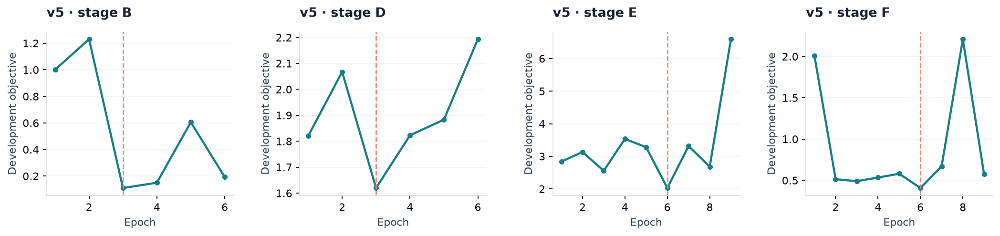

Data,Stage,Task,Epoch,N,F1,ROC AUC,AP
v5,B,atomic,3,1274,0.9068,0.9960,0.9790
v5,F,atomic,6,1274,0.9100,0.9943,0.9763
v5,F,combined,6,1177,0.9930,0.9962,0.9949
v5,F,association,6,258,0.9575,0.9928,0.9916


In [11]:
baseline = json.loads((PROJECT / "assets/v5_development.json").read_text())
assert baseline["dataset_hash"] == stats["v5"].get("dataset_hash", "eb85185d55fa6b737934bbbe49cd88349e1983d45ad5afc8a22737d14de36e62")
fig, axes = plt.subplots(1, 4, figsize=(13.2, 3.2))
for axis, name in zip(axes, "BDEF"):
    record = baseline["stages"][name]
    x = [row["epoch"] for row in record["curve"]]
    y = [row["loss"] for row in record["curve"]]
    axis.plot(x, y, color=TEAL, marker="o", markersize=4, linewidth=2)
    axis.axvline(record["best_epoch"], linestyle="--", color=CORAL, linewidth=1.2)
    axis.set_title(f"v5 · stage {name}", loc="left", pad=14)
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Development objective")
    axis.grid(axis="y", alpha=.15)
fig.tight_layout(w_pad=2)
plt.show()

baseline_rows = []
for name, path in [("B", "atomic"), ("F", "atomic"), ("F", "combined"), ("F", "association")]:
    record = baseline["stages"][name]
    values = record["development_metrics"][path]
    values = values if path == "association" else values["overall"]
    fmt = lambda value: "—" if value is None else f"{value:.4f}"
    baseline_rows.append(["v5", name, path, record["best_epoch"], values["n"],
        fmt(values.get("f1")), fmt(values.get("roc_auc")), fmt(values.get("auprc"))])
table(["Data", "Stage", "Task", "Epoch", "N", "F1", "ROC AUC", "AP"], baseline_rows,
      "v5 development only. These are neither performance results for the new v6 nor an independent test evaluation.")


### Evaluation protocol

For the overall and category heads, precision, recall, F1, ROC AUC, average precision, Brier score, and ECE are computed with masks applied. Association has separate metrics and support counts for classes and scenario families.
Repeated training tasks do not double the denominator of development metrics.

Calibration is reserved for separate calibration fitting, threshold_validation for threshold selection, and test for final evaluation after the model and decisions have been fixed. The current v6 lacks sufficient independent annotations for justified acceptance: numbers can be computed using existing labels, but they cannot be described as validated performance on real users.


<a id="inference"></a>
## 07 · Usage and saving

The demonstration uses safe examples: continuation of a consent-based workflow and a message on a different topic. The system stores vectors and structural provenance, rather than source texts. Composition preserves message order and checks whether the combination is valid.

Without separate calibration, the values below are **raw sigmoid scores**, not validated probabilities.
In `demo` mode, they serve only to check the interface.


In [12]:
engine = TrajectoryEngine(restored)
example_texts = [
    "I can help organize a consent-based wildlife camera survey and record the approved locations.",
    "For that same wildlife survey, keep the camera schedule and consent records in the project log.",
    "For a different task, here is a plan to practice multiplication tables each morning.",
]
inference_rows = []
for position, text in enumerate(example_texts):
    result = engine.ingest(f"example-{position}", text, session="notebook-demo", position=position)
    assert math.isfinite(result["risk"]) and 0 <= result["risk"] <= 1
    inference_rows.append([position+1, text, f'{result["risk"]:.4f}'])
table(["Response", "Text", "Raw overall score"], inference_rows)

comparison_rows = []
for left, right in [("example-0", "example-1"), ("example-0", "example-2")]:
    merged = engine.compose(left, right)
    comparison_rows.append([left + " + " + right, f'{merged["association"]:.4f}', f'{merged["risk"]:.4f}'])
table(["Combination", "Raw association score", "Raw risk score"], comparison_rows,
      "For the tiny model, scores from a randomly initialized encoder do not support semantic conclusions.")

engine.save(RUN / "vector-state.json")
saved_state = json.loads((RUN / "vector-state.json").read_text())
assert not any(text in json.dumps(saved_state) for text in example_texts)
print("State saved; it contains no source texts.")


Response,Text,Raw overall score
1,I can help organize a consent-based wildlife camera survey and record the approved locations.,0.4387
2,"For that same wildlife survey, keep the camera schedule and consent records in the project log.",0.4676
3,"For a different task, here is a plan to practice multiplication tables each morning.",0.4524


Combination,Raw association score,Raw risk score
example-0 + example-1,0.5118,0.2233
example-0 + example-2,0.5071,0.2368


State saved; it contains no source texts.


### Optional export

After full training, `RUN_ONNX_EXPORT` can be enabled. Export verification compares ONNX Runtime and PyTorch on fixed inputs. The export includes separate encoder, window aggregation, and composer graphs; verified computational equivalence does not replace performance evaluation.


In [13]:
if RUN_ONNX_EXPORT and MODE == "train":
    export_requirements = {"onnx": "onnx>=1.17,<2", "onnxruntime": "onnxruntime>=1.20,<2"}
    export_missing = [package for module, package in export_requirements.items() if not available(module)]
    if export_missing:
        if not INSTALL_MISSING:
            raise RuntimeError("Export libraries are required: " + " ".join(export_missing))
        subprocess.run([sys.executable, "-m", "pip", "install", *export_missing], check=True)
        importlib.invalidate_caches()
    from trajectory_risk.export_onnx import export_bundle
    verification = export_bundle(RUN / "F/student.pt", RUN / "export-v2")
    print(json.dumps(verification, ensure_ascii=False, indent=2))
else:
    print("ONNX export is disabled. It requires MODE='train' and RUN_ONNX_EXPORT=True.")


ONNX export is disabled. It requires MODE='train' and RUN_ONNX_EXPORT=True.


<a id="conclusion"></a>
## 08 · Conclusions

1. A combined corpus of **29,004 responses** was prepared with explicit masks for unknown targets and record provenance. The overall train label became more balanced: **24.5% → 40.4%** positive singleton responses.
2. A unified assessment of singleton and combined representations was implemented. Long responses are covered by windows, while association between messages is learned separately from overall harmfulness.
3. The B → cache → D → E → assemble → F path is reproducible. The notebook checks data identity, exclusion of unknown targets from the loss, cache contents, and checkpoint restoration.
4. The saved DeBERTa results refer to **v5 development**. The new v6 requires its own full experiment and independent label validation; a diagnostic tiny-model run does not replace these.

Next steps: correct disputed positive labels under the response-only rubric, expand independent category annotations and real related histories, then compare v5/v6 on a single dataset fixed in advance. Applicability to Russian has not been established separately.

### Sources and terms of use

| Source | Contribution | Data license |
|---|---|---|
| [PKU-SafeRLHF](https://huggingface.co/datasets/PKU-Alignment/PKU-SafeRLHF) | 7,998 new responses | CC BY-NC 4.0 |
| [BeaverTails](https://huggingface.co/datasets/PKU-Alignment/BeaverTails) | 7,319 new responses | CC BY-NC 4.0 |
| [Do-Not-Answer](https://github.com/Libr-AI/do-not-answer) | 2,752 new responses | CC BY-NC-SA 4.0 as explicitly declared on GitHub |
| [PolyGuardMix](https://huggingface.co/datasets/ToxicityPrompts/PolyGuardMix) | Public portion of the existing v5 | CC BY 4.0 |
| Authored v5 scenarios | Categories, contrasts, and associations | CC0 1.0 according to project provenance |

The compilation is intended for noncommercial use. Attribution, pinned revisions, notices about differing license metadata, and original source cards are preserved inside the notebook.
The compilation does not replace source terms with a new blanket permissive license.
DeBERTa revision: `8ccc9b6f36199bec6961081d44eb72fb3f7353f3`.


In [14]:
# Current run summary: a compact machine-readable report alongside the checkpoint.
summary = {
    "notebook": "trajectory-risk-submission-v1", "mode": MODE,
    "model_backend": config.backend, "device": config.device, "seed": SEED,
    "dataset_hash_full_v6": digest(raw), "training_dataset_hash": expected_hash,
    "messages": len(experiment_data.messages), "pairs": len(experiment_data.pairs),
    "stages": [row[0] for row in timings], "checks_passed": len(checks),
    "deberta_v6_training_executed": MODE == "train",
    "independent_test_evaluation_executed": False,
    "checkpoint": "F/student.pt", "state": "vector-state.json",
}
(RUN / "notebook-summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2))
card("Run reproduced", "Data processing, training, model restoration, and usage examples have completed. The final report and checkpoint are in the current run's working directory.")
table(["For submission", "To continue training"], [
    ["This .ipynb: text, charts, results, code, and data", "Save the .trajectory-risk working directory with weights and logs"],
    ["Separate caches and raw exports are not required", "Best checkpoint: F/student.pt within the current run"],
])


For submission,To continue training
"This .ipynb: text, charts, results, code, and data",Save the .trajectory-risk working directory with weights and logs
Separate caches and raw exports are not required,Best checkpoint: F/student.pt within the current run


<a id="implementation"></a>
## 09 · Appendix: source implementation

The exact code executed above is displayed below. These are the original project modules, not a simplified model rewritten for presentation. Their contents are verified by checksums.
This section can remain collapsed while reading the main report.


In [15]:
descriptions = {
    "windowing": "Token windows and coverage geometry", "model": "Encoder, aggregation, heads, and composer",
    "training": "Loss functions and training loops", "workflow": "Stages, caching, and checkpoint assembly",
    "runtime": "Inference and vector-state storage", "contracts": "Data contract and partitioning",
}
panels = []
for module, description in descriptions.items():
    source = (PROJECT / "trajectory_risk" / (module + ".py")).read_text()
    panels.append('<details style="border:1px solid #dce4eb;border-radius:9px;padding:13px 16px;margin:10px 0">'
        + '<summary style="cursor:pointer;font-weight:700;color:#177e89">'
        + html.escape(description + " · " + module + ".py") + '</summary>'
        + '<pre style="font-size:12px;line-height:1.55;overflow:auto;max-height:620px;background:#f5f7fa;padding:16px;border-radius:8px">'
        + html.escape(source) + '</pre></details>')
display(HTML(''.join(panels)))


<div style="border-top:2px solid #177e89;margin-top:24px;padding-top:18px;color:#63748a;font-size:12px">
Trajectory Risk · educational research project · v6 data · reproducible notebook<br>
Observed results, diagnostic checks, and as-yet untested assumptions are explicitly distinguished.
</div>
